In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from tqdm import tqdm

In [2]:
def run_dir(stem):
    return (
        "../../result/HEK293T_HCT116/coemb/"
        f"{stem}_HCT116anchor"
    )


def load_support(stem):
    return pd.read_csv(
        f"{run_dir(stem)}/HEK293T/HEK293T_support.tsv",
        sep="\t",
        index_col=0,
    ).sort_index()


support_list = [
    load_support(stem)
    for stem in ["promergeclub", "promergesubtract"]
]
assert all(s.equals(support_list[0]) for s in support_list[1:])
support = support_list[0]

names = support.index[support["base"] == 1]
measured = support.loc[names, ["BioPlex", "SECMX"]].astype(bool)
coverage = pd.Series(
    [
        {
            (True, True): "AP-MS and SEC-MS",
            (True, False): "AP-MS only",
            (False, True): "SEC-MS only",
        }[tuple(row)]
        for row in measured.values
    ],
    index=names,
)
both = coverage.index[coverage == "AP-MS and SEC-MS"]

In [3]:
def load_score(stem):
    frame = pd.read_csv(
        f"{run_dir(stem)}/HEK293T/HEK293T_specific_score.tsv",
        sep="\t",
        index_col=0,
    )
    return frame["specific_score"].astype(float)


score = pd.DataFrame(
    {
        label: load_score(stem).reindex(names)
        for label, stem in [
            ("ProMERGE", "promergeclub"),
            ("Subtract", "promergesubtract"),
        ]
    }
)

In [4]:
partners = {}
for modality in ["BioPlex", "SECMX"]:
    ppi = pd.read_csv(
        f"../../result/HEK293T_HCT116/input/{modality}-HCT116.ppi",
        sep="\t",
    )
    for a, b in zip(ppi["GeneA"], ppi["GeneB"]):
        partners.setdefault(a, set()).add(b)
        partners.setdefault(b, set()).add(a)

degree = pd.Series(
    {gene: len(genes) for gene, genes in partners.items()}
).reindex(names).fillna(0)

In [5]:
def load_base_latent(stem):
    return pd.read_csv(
        f"{run_dir(stem)}/HCT116/HCT116_latent.tsv",
        sep="\t",
        index_col=0,
    ).sort_index()


base_list = [
    load_base_latent(stem)
    for stem in ["promergeclub", "promergesubtract"]
]
for label, frame in zip(["Subtract"], base_list[1:]):
    common = base_list[0].index.intersection(frame.index)
    gap = np.abs(
        base_list[0].loc[common].values - frame.loc[common].values
    ).max()

In [6]:
def knn_mean_cosine(unit, k, chunk=2000):
    unit = unit.astype(np.float32)
    n = unit.shape[0]
    out = np.empty(n, dtype=np.float64)
    for start in range(0, n, chunk):
        stop = min(start + chunk, n)
        sim = unit[start:stop] @ unit.T
        sim[np.arange(stop - start), np.arange(start, stop)] = -np.inf
        top = np.partition(sim, n - k, axis=1)[:, n - k:]
        out[start:stop] = top.mean(axis=1)
    return out


base_values = base_list[0].values.astype(np.float64)
base_unit = base_values / np.maximum(
    np.linalg.norm(base_values, axis=1, keepdims=True),
    1e-12,
)
hubness = pd.Series(
    knn_mean_cosine(base_unit, 10),
    index=base_list[0].index,
).reindex(names)

### Strata

In [7]:
def tertile(values):
    ranked = values.rank(method="average")
    return pd.qcut(ranked, 3, labels=["Low", "Mid", "High"])


# group, row label, proteins
strata = [
    ("Coverage", label, coverage.index[coverage == label])
    for label in ["AP-MS and SEC-MS", "AP-MS only", "SEC-MS only"]
]
for group, values, fmt in [
    ("Base degree", degree, "{:.0f}"),
    ("Anchor hubness", hubness, "{:.2f}"),
]:
    inside = values.reindex(both)
    bins = tertile(inside)
    for level in ["Low", "Mid", "High"]:
        members = bins.index[bins == level]
        lo = fmt.format(inside[members].min())
        hi = fmt.format(inside[members].max())
        row = f"{level} {group.split()[-1]} ({lo}-{hi})"
        strata.append((group, row, members))

### AUROC and paired bootstrap

In [8]:
def load_gene_set(name):
    with open(f"../../result/reference/{name}", "r") as handle:
        return set(line.strip() for line in handle if line.strip())


gold_standard_list = [
    load_gene_set(name)
    for name in [
        "HEK293T-HCT116_abundanceTMT.genes",
        "HEK293T-HCT116_RNA.genes",
        "HEK293T-HCT116_stress.genes",
    ]
]
background_list = [
    load_gene_set(name)
    for name in [
        "HEK293T-HCT116_abundanceTMT.background",
        "HEK293T-HCT116_RNA.background",
        "HEK293T-HCT116_stress.background",
    ]
]

score_mat = np.nan_to_num(
    score[["ProMERGE", "Subtract"]].values.T.astype(np.float64)
)
n_unit = len(names)
position = pd.Series(np.arange(n_unit), index=names)

In [9]:
def sort_by_score(score, label):
    """
    Sort one run's units by score once and record where each block of
    tied scores starts.
    """
    order = np.argsort(score, kind="stable")
    score_sorted = score[order]
    group_start = np.flatnonzero(
        np.r_[True, score_sorted[1:] != score_sorted[:-1]]
    )
    return order, label[order], group_start


def weighted_auroc(label_sorted, weight_sorted, group_start):
    """
    AUROC in Mann-Whitney U form, each unit counted weight times and
    tied scores sharing half credit.
    """
    pos = weight_sorted * label_sorted
    neg = weight_sorted - pos
    pos_g = np.add.reduceat(pos, group_start)
    neg_g = np.add.reduceat(neg, group_start)
    below = np.cumsum(neg_g) - neg_g
    u = np.dot(pos_g, below + 0.5 * neg_g)
    return float(u / (pos_g.sum() * neg_g.sum()))

In [10]:
# one entry per stratum and reference, scored on the stratum's
# proteins inside the reference background
combo_list = []
for group, row, members in strata:
    for rr, ref_short in enumerate([
        "Differential abundance",
        "Differential expression",
        "Differential stress",
    ]):
        keep = members[members.isin(background_list[rr])]
        label = keep.isin(gold_standard_list[rr]).astype(np.float64)
        n_pos = int(label.sum())
        combo = {
            "group": group,
            "stratum": row,
            "reference": ref_short,
            "n_protein": len(keep),
            "n_positive": n_pos,
            "idx": position[keep].values,
            "scored": min(n_pos, len(keep) - n_pos) >= 10,
        }
        if combo["scored"]:
            combo["sorted"] = [
                sort_by_score(score_mat[mm][combo["idx"]], label)
                for mm in range(2)
            ]
            combo["auc"] = [
                roc_auc_score(label, score_mat[mm][combo["idx"]])
                for mm in range(2)
            ]
            # check that unit weights reproduce roc_auc_score
            check = [
                weighted_auroc(
                    label_sorted,
                    np.ones(len(keep)),
                    group_start,
                )
                for _, label_sorted, group_start in combo["sorted"]
            ]
            assert np.allclose(check, combo["auc"]), (group, row)
        combo_list.append(combo)
n_combo = len(combo_list)

In [11]:
# every draw resamples all proteins once and is shared by both runs,
# so the difference is paired
rng = np.random.default_rng(1)
auc_boot = np.full((10000, n_combo, 2), np.nan)
scored_idx = [cc for cc, c in enumerate(combo_list) if c["scored"]]

with np.errstate(divide="ignore", invalid="ignore"):
    for bb in tqdm(range(10000)):
        weight = np.bincount(
            rng.integers(0, n_unit, n_unit),
            minlength=n_unit,
        ).astype(np.float64)
        for cc in scored_idx:
            combo = combo_list[cc]
            w = weight[combo["idx"]]
            for mm, (order, label_sorted, group_start) in enumerate(
                combo["sorted"]
            ):
                auc_boot[bb, cc, mm] = weighted_auroc(
                    label_sorted,
                    w[order],
                    group_start,
                )

100%|██████████| 10000/10000 [00:26<00:00, 374.12it/s]


In [12]:
row_list = []
for cc, combo in enumerate(combo_list):
    row = {
        key: combo[key]
        for key in [
            "group",
            "stratum",
            "reference",
            "n_protein",
            "n_positive",
        ]
    }
    if combo["scored"]:
        for mm, label in enumerate(["ProMERGE", "Subtract"]):
            boot = auc_boot[:, cc, mm]
            row[f"auc_{label}"] = combo["auc"][mm]
            row[f"lo_{label}"] = np.nanpercentile(boot, 2.5)
            row[f"hi_{label}"] = np.nanpercentile(boot, 97.5)
        delta_boot = auc_boot[:, cc, 0] - auc_boot[:, cc, 1]
        delta_boot = delta_boot[np.isfinite(delta_boot)]
        n_valid = len(delta_boot)
        p_lower = (np.sum(delta_boot <= 0) + 1) / (n_valid + 1)
        p_upper = (np.sum(delta_boot >= 0) + 1) / (n_valid + 1)
        row["delta"] = combo["auc"][0] - combo["auc"][1]
        row["delta_lo"] = np.percentile(delta_boot, 2.5)
        row["delta_hi"] = np.percentile(delta_boot, 97.5)
        row["p_boot"] = min(2 * min(p_lower, p_upper), 1.0)
    row_list.append(row)

stat_df = pd.DataFrame(row_list)

### Forest plot of the difference

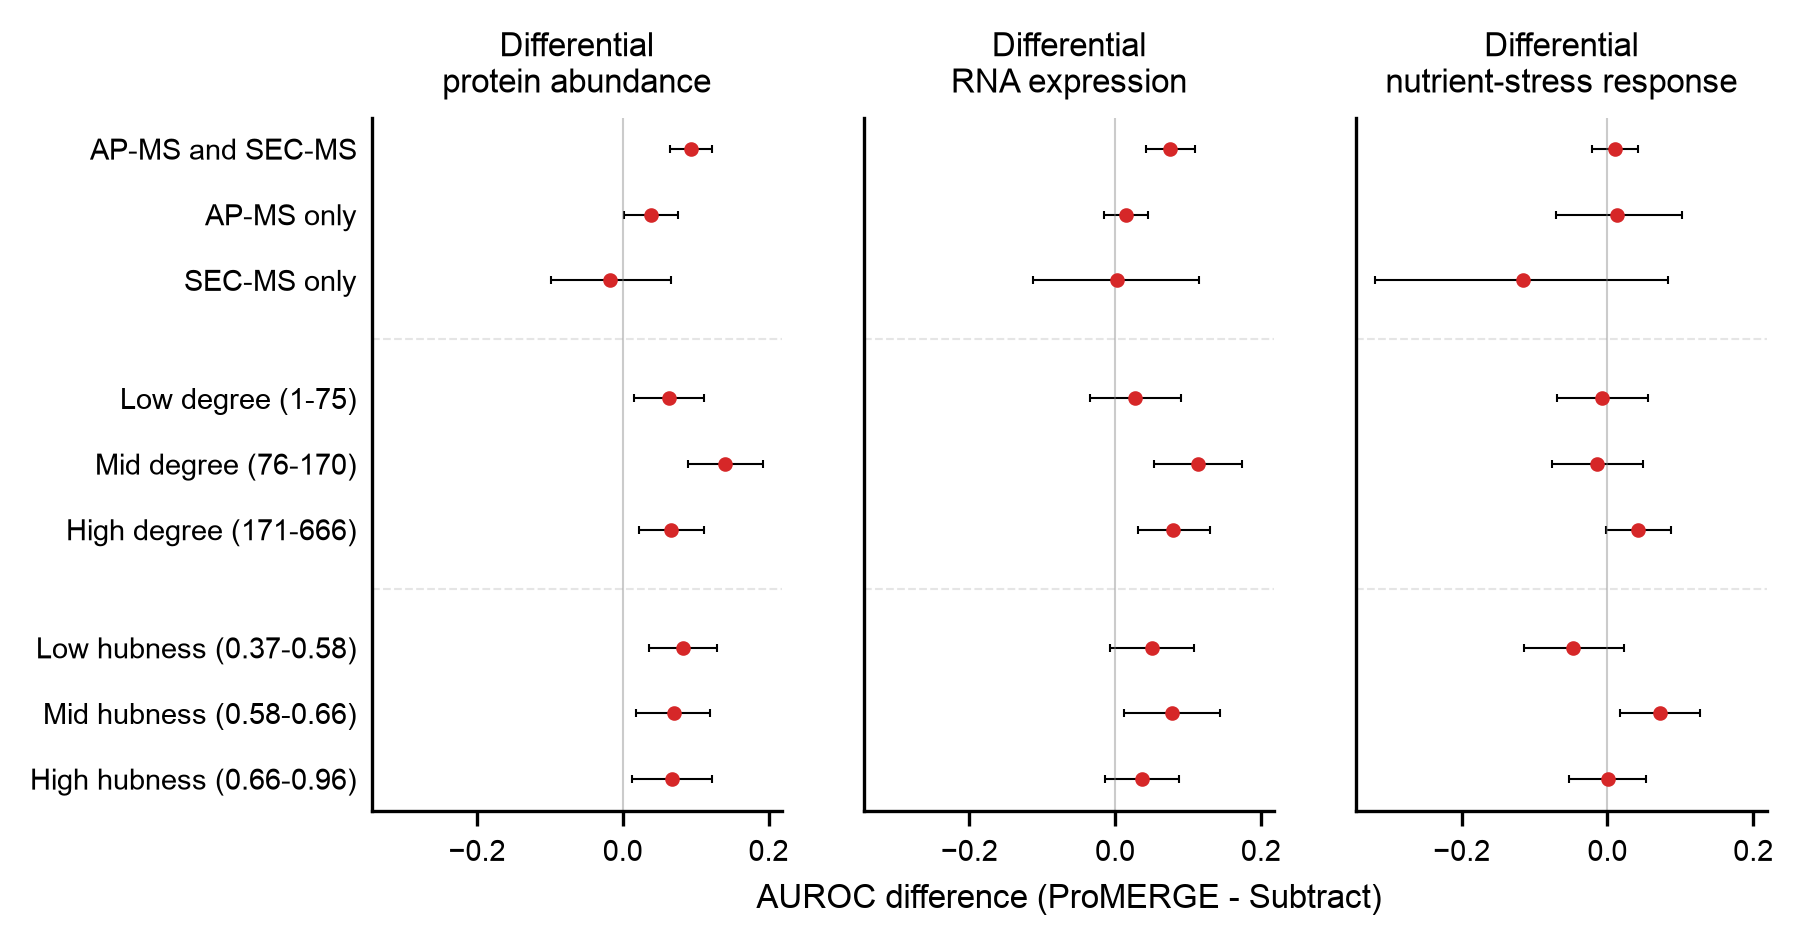

In [13]:
# y position of every stratum, groups separated by 0.8
row_order = [(group, row) for group, row, _ in strata]
y_list = []
y = 0.0
previous = None
for group, _ in row_order:
    if previous is not None and group != previous:
        y += 0.8
    y_list.append(y)
    y += 1.0
    previous = group
y_of = dict(zip(row_order, y_list))
gap_y = [
    y_list[ii] - (1.0 + 0.8) / 2
    for ii in range(1, len(row_order))
    if row_order[ii][0] != row_order[ii - 1][0]
]

plt.style.use("/home/jig049/misc/style.mplstyle")
fig, axes = plt.subplots(
    1,
    3,
    figsize=(6, 3),
    dpi=300,
    sharex=True,
    sharey=True,
)

for ax, (ref_label, ref_short) in zip(axes, [
    ("Differential\nprotein abundance", "Differential abundance"),
    ("Differential\nRNA expression", "Differential expression"),
    ("Differential\nnutrient-stress response", "Differential stress"),
]):
    frame = stat_df[
        (stat_df["reference"] == ref_short)
        & stat_df["delta"].notna()
    ]
    yy = np.array([
        y_of[(g, r)] for g, r in zip(frame["group"], frame["stratum"])
    ])
    ax.errorbar(
        x=frame["delta"],
        y=yy,
        xerr=np.vstack([
            frame["delta"] - frame["delta_lo"],
            frame["delta_hi"] - frame["delta"],
        ]),
        color="tab:red",
        marker="o",
        linestyle="",
        ms=2.5,
        ecolor="black",
        elinewidth=0.5,
        capsize=1,
        capthick=0.5,
    )
    ax.axvline(0, color="tab:grey", alpha=0.4, lw=0.5)
    for gy in gap_y:
        ax.axhline(
            gy,
            color="tab:grey",
            alpha=0.2,
            lw=0.5,
            linestyle="--",
        )
    ax.set_title(ref_label, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

# one x range for all panels so the references compare directly
x_lo = stat_df["delta_lo"].min()
x_hi = stat_df["delta_hi"].max()
x_pad = 0.05 * (x_hi - x_lo)
axes[0].set_xlim([x_lo - x_pad, x_hi + x_pad])
axes[0].xaxis.set_major_locator(plt.MultipleLocator(0.2))
axes[0].set_yticks(y_list, labels=[row for _, row in row_order])
axes[0].invert_yaxis()
for ax in axes:
    ax.tick_params(axis="y", length=0)
axes[1].set_xlabel(
    "AUROC difference (ProMERGE - Subtract)",
    fontsize=8,
)

fig.savefig(
    "./figS19_club_vs_subtract.pdf",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

In [14]:
rank_pct = score.loc[both, ["ProMERGE", "Subtract"]].rank(pct=True)
rho = spearmanr(rank_pct["ProMERGE"], rank_pct["Subtract"])[0]
top = rank_pct >= 1 - 0.1
n_shared = int((top["ProMERGE"] & top["Subtract"]).sum())
print(f"Spearman rho {rho:.3f}")

Spearman rho 0.537
